# BERN02 – Hierarchical Models and Testing

## Towel Reuse Study

Author: Ran Tao

Course: BERN02

Software: Python, Bambi, ArviZ

## 1. Introduction

The data come from several randomized case-control studies investigating whether a social-norm intervention affects hotel guests' towel reuse behaviour.

The main research question is whether the social-norm intervention changes the probability that a guest reuses their towel.

Since the data come from several different studies, the studies may differ in their baseline towel reuse rates. Therefore, the analysis should account for between-study heterogeneity rather than treating all observations as independent observations from one common population.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import bambi as bmb
import arviz as az
import pytensor
pytensor.config.cxx = ""

In [2]:
data = pd.read_csv(
    "towelData.csv",
    sep=";",
    encoding="latin1"
)

data.head()

,Source,AuthorName,Experiment,Year,Group,Towel.Reuse,Count
0,Goldstein.2008.Ex1,Goldstein et al.,1,2008,Control,Yes,74
1,Goldstein.2008.Ex1,Goldstein et al.,1,2008,Social Norm,Yes,98
2,Goldstein.2008.Ex1,Goldstein et al.,1,2008,Control,No,137
3,Goldstein.2008.Ex1,Goldstein et al.,1,2008,Social Norm,No,124
4,Goldstein.2008.Ex2,Goldstein et al.,2,2008,Control,Yes,103


## 2. Data

The dataset contains information from seven study/experiment units.

For each study and treatment group, the data record the number of guests who reused their towel and the number who did not.

The two groups are:

- **Control:** no social-norm intervention
- **Social Norm:** social-norm intervention

The response variable is therefore a binomial count: the number of guests who reused their towel out of the total number of guests in each study and group.

In [3]:
print("Number of rows:", len(data))
print("Number of studies:", data["Source"].nunique())
print("\nColumns:")
print(data.columns.tolist())

print("\nMissing values:")
print(data.isna().sum())

Number of rows: 28
Number of studies: 7

Columns:
['Source', 'AuthorName', 'Experiment', 'Year', 'Group', 'Towel.Reuse', 'Count']

Missing values:
Source         0
AuthorName     0
Experiment     0
Year           0
Group          0
Towel.Reuse    0
Count          0
dtype: int64


In [4]:
count = data["Count"].to_numpy()

control_yes = count[::4]
social_yes = count[1::4]

control_no = count[2::4]
social_no = count[3::4]

control_total = control_yes + control_no
social_total = social_yes + social_no

study_names = data["Source"].unique()

control_data = pd.DataFrame({
    "reuse": control_yes,
    "total": control_total,
    "group": "Control",
    "study": study_names
})

social_data = pd.DataFrame({
    "reuse": social_yes,
    "total": social_total,
    "group": "Social Norm",
    "study": study_names
})

combined_data = pd.concat(
    [control_data, social_data],
    ignore_index=True
)

combined_data["group"] = combined_data["group"].astype("category")
combined_data["study"] = combined_data["study"].astype("category")

combined_data["intervention"] = (
    combined_data["group"] == "Social Norm"
).astype(int)

combined_data["reuse_rate"] = (
    combined_data["reuse"] / combined_data["total"]
)

combined_data

,reuse,total,group,study,intervention,reuse_rate
0,74,211,Control,Goldstein.2008.Ex1,0,0.350711
1,103,277,Control,Goldstein.2008.Ex2,0,0.371841
2,77,135,Control,Schulz2008.Ex2,0,0.570370
3,82,187,Control,Schulz2008.Ex3,0,0.438503
4,21,25,Control,Mair2010,0,0.840000
5,123,147,Control,Bohner2014.Ex1,0,0.836735
6,28,30,Control,Bohner2014.Ex2,0,0.933333
7,98,222,Social Norm,Goldstein.2008.Ex1,1,0.441441
8,587,1318,Social Norm,Goldstein.2008.Ex2,1,0.445372
9,406,655,Social Norm,Schulz2008.Ex2,1,0.619847


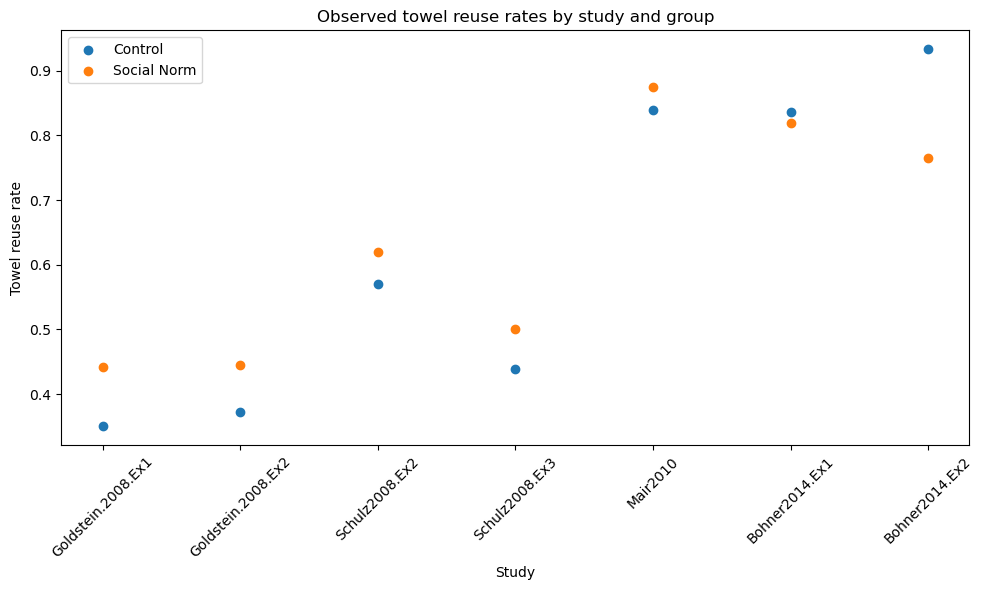

In [5]:
plt.figure(figsize=(10, 6))

for group in ["Control", "Social Norm"]:
    group_data = combined_data[
        combined_data["group"] == group
    ]

    plt.scatter(
        group_data["study"],
        group_data["reuse_rate"],
        label=group
    )

plt.xlabel("Study")
plt.ylabel("Towel reuse rate")
plt.title("Observed towel reuse rates by study and group")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

## 3. Statistical model

The response consists of the number of guests who reused their towel out of a known total number of guests. A binomial likelihood is therefore appropriate.

Let $Y_{ij}$ denote the number of guests who reuse their towel in study $j$ and group $i$, and let $n_{ij}$ denote the corresponding total number of guests.

We assume

$$
Y_{ij} \sim \text{Binomial}(n_{ij},p_{ij}).
$$

The probability of towel reuse is modelled using a logistic link:

$$
\text{logit}(p_{ij})=\alpha_j+\beta X_{ij},
$$

where $X_{ij}=0$ for the Control group and $X_{ij}=1$ for the Social Norm group.

The study-specific intercept is modelled hierarchically:

$$
\alpha_j \sim N(\mu_\alpha,\sigma_\alpha).
$$

Here, $\beta$ represents the common intervention effect on the log-odds scale, while $\sigma_\alpha$ represents between-study heterogeneity in the baseline probability of towel reuse.

In [6]:
model = bmb.Model(
    "p(reuse, total) ~ intervention + (1 | study)",
    combined_data,
    family="binomial",
    link="logit"
)

print(model)

       Formula: p(reuse, total) ~ intervention + (1 | study)
        Family: binomial
          Link: p = logit
  Observations: 14
        Priors: 
    target = p
        Common-level effects
            Intercept ~ Normal(mu: 0.0, sigma: 1.5)
            intervention ~ Normal(mu: 0.0, sigma: 2.0)
        
        Group-level effects
            1|study ~ Normal(mu: 0.0, sigma: HalfNormal(sigma: 2.6926))


### Prior distributions

Bambi assigns weakly informative default priors to the model parameters. In the fitted model, the common intercept has a Normal prior and the intervention effect has a Normal prior. The standard deviation of the study-level random effects has a Half-Normal prior.

These priors provide regularization while allowing a reasonably wide range of values for the intervention effect and between-study heterogeneity.

In [7]:
print(model)

       Formula: p(reuse, total) ~ intervention + (1 | study)
        Family: binomial
          Link: p = logit
  Observations: 14
        Priors: 
    target = p
        Common-level effects
            Intercept ~ Normal(mu: 0.0, sigma: 1.5)
            intervention ~ Normal(mu: 0.0, sigma: 2.0)
        
        Group-level effects
            1|study ~ Normal(mu: 0.0, sigma: HalfNormal(sigma: 2.6926))


In [8]:
idata = model.fit(
    draws=1000,
    tune=1000,
    chains=4,
    cores=1,
    target_accept=0.95,
    random_seed=123
)

Initializing NUTS using jitter+adapt_diag...
Sequential sampling (4 chains in 1 job)
NUTS: [Intercept, intervention, 1|study_sigma, 1|study_offset]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 53 seconds.


## 4. Bayesian inference and convergence diagnostics

Posterior summaries are reported using posterior means and 90% probability intervals. Convergence is assessed using the \(\hat{R}\) diagnostic and effective sample sizes.

In [9]:
summary = az.summary(
    idata,
    var_names=[
        "Intercept",
        "intervention",
        "1|study_sigma"
    ],
    ci_prob=0.90
)

print(summary)

               mean    sd eti90_lb eti90_ub ess_bulk ess_tail r_hat mcse_mean mcse_sd
Intercept      0.41  0.44    -0.28      1.1      782     1078  1.00     0.016   0.016
intervention   0.21  0.08    0.076     0.34     2233     2011  1.00    0.0017  0.0015
1|study_sigma  1.14  0.45     0.64        2      846     1297  1.00     0.015   0.019


In [10]:
diagnostics = az.summary(
    idata,
    var_names=[
        "Intercept",
        "intervention",
        "1|study_sigma"
    ],
    ci_prob=0.90
)[[
    "mean",
    "sd",
    "ess_bulk",
    "ess_tail",
    "r_hat"
]]

print(diagnostics)

               mean    sd ess_bulk ess_tail r_hat
Intercept      0.41  0.44      782     1078  1.00
intervention   0.21  0.08     2233     2011  1.00
1|study_sigma  1.14  0.45      846     1297  1.00


All reported parameters have $\hat{R}=1.00$, indicating good agreement between the MCMC chains. The effective sample sizes are also sufficiently large relative to the number of posterior draws.

In [11]:
beta = idata.posterior["intervention"].values.flatten()

beta_mean = np.mean(beta)
beta_lower = np.quantile(beta, 0.05)
beta_upper = np.quantile(beta, 0.95)

print(f"Posterior mean beta: {beta_mean:.3f}")
print(
    f"90% probability interval: "
    f"[{beta_lower:.3f}, {beta_upper:.3f}]"
)

Posterior mean beta: 0.210
90% probability interval: [0.076, 0.340]


## 5. Hypothesis testing

We are interested in whether the social-norm intervention increases the probability of towel reuse.

The hypotheses are

$$
H_0:\beta \leq 0
$$

versus

$$
H_1:\beta > 0.
$$

In the Bayesian framework, this can be assessed directly from the posterior distribution by calculating

$$
P(\beta>0\mid\text{data}).
$$

In [12]:
prob_positive = np.mean(beta > 0)

print(
    f"P(beta > 0 | data) = {prob_positive:.4f}"
)

P(beta > 0 | data) = 0.9955


In [13]:
odds_ratio = np.exp(beta)

or_mean = np.mean(odds_ratio)
or_lower = np.quantile(odds_ratio, 0.05)
or_upper = np.quantile(odds_ratio, 0.95)

print(f"Posterior mean odds ratio: {or_mean:.3f}")
print(
    f"90% probability interval for odds ratio: "
    f"[{or_lower:.3f}, {or_upper:.3f}]"
)

Posterior mean odds ratio: 1.238
90% probability interval for odds ratio: [1.079, 1.406]


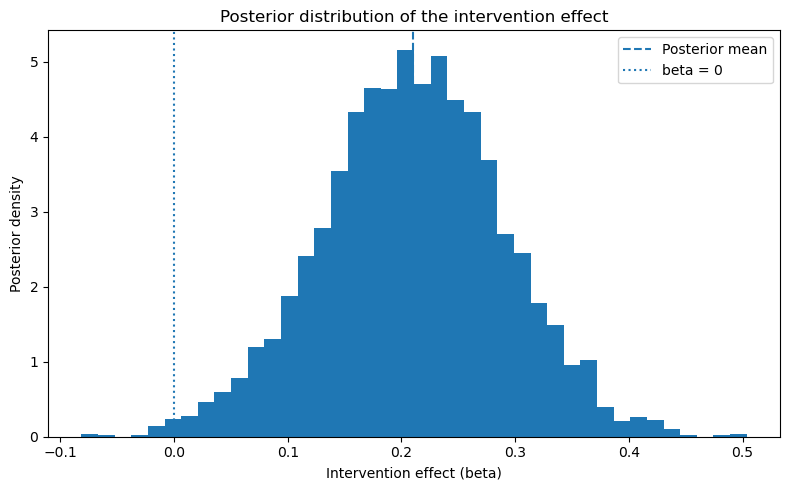

In [14]:
plt.figure(figsize=(8, 5))

plt.hist(beta, bins=40, density=True)

plt.axvline(
    beta_mean,
    linestyle="--",
    label="Posterior mean"
)

plt.axvline(
    0,
    linestyle=":",
    label="beta = 0"
)

plt.xlabel("Intervention effect (beta)")
plt.ylabel("Posterior density")
plt.title("Posterior distribution of the intervention effect")
plt.legend()
plt.tight_layout()
plt.show()

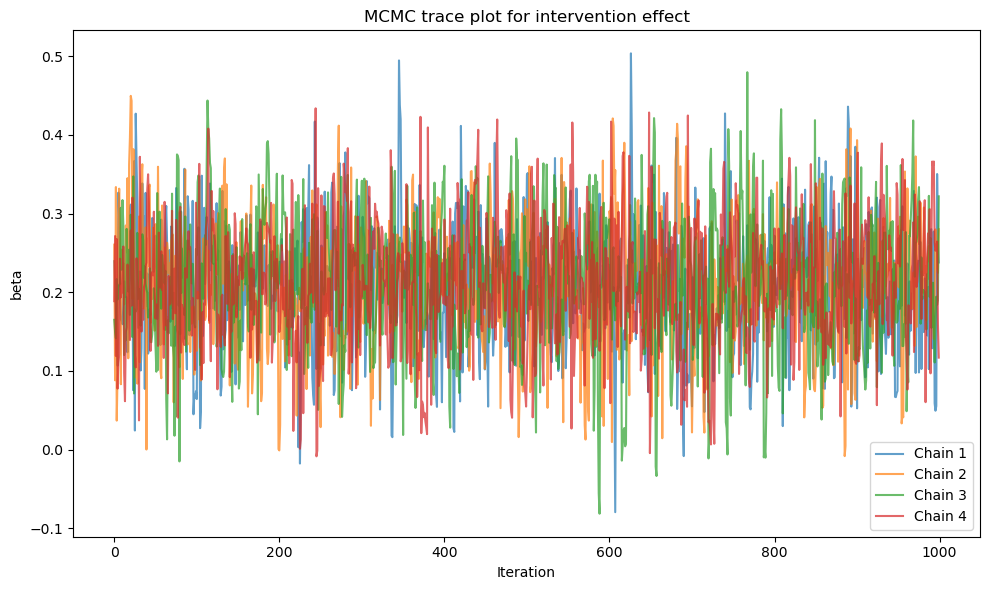

In [15]:
beta_chains = idata.posterior["intervention"].values

plt.figure(figsize=(10, 6))

for chain in range(beta_chains.shape[0]):
    plt.plot(
        beta_chains[chain],
        alpha=0.7,
        label=f"Chain {chain + 1}"
    )

plt.xlabel("Iteration")
plt.ylabel("beta")
plt.title("MCMC trace plot for intervention effect")
plt.legend()
plt.tight_layout()
plt.show()

## 6. Discussion

The hierarchical structure allows the baseline towel reuse probability to vary between studies. This is important because the observed reuse rates differ considerably between studies.

The estimated between-study standard deviation indicates substantial variation in baseline log-odds between studies. At the same time, the posterior distribution of the intervention coefficient is concentrated above zero.

The hierarchical model therefore separates variation between studies from the common intervention effect, rather than assuming that all studies have exactly the same baseline reuse probability.

## 7. Conclusion

The analysis used a hierarchical Bayesian binomial logistic regression model to investigate the effect of the social-norm intervention on hotel towel reuse.

The posterior distribution of the intervention effect was concentrated above zero, with a posterior probability of approximately 0.996 that the intervention effect is positive.

The estimated intervention effect was approximately 0.21 on the log-odds scale, corresponding to an odds ratio of approximately 1.24.